<a href="https://colab.research.google.com/github/lari-cmd/python-practice-algos-1/blob/student/636-01/hw_7_borisova_m_m.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 🎯 Задание для самостоятельной работы (ДЗ 7)

1. Загрузите датасет **Breast Cancer** (`sklearn.datasets.load_breast_cancer`).
2. Обучите `RandomForestClassifier` на исходных 30 признаках и замерьте accuracy.
3. Примените `PCA(n_components=0.95)` (сохранив 95% дисперсии).
4. Обучите ту же модель на сжатых признаках. Упало ли качество? Насколько сильно?
5. Попробуйте визуализировать данные через `UMAP` и раскрасить по целевому классу (malignant/benign).

*Цель: понять, что понижение размерности может как ускорять модель, так и немного снижать точность, и научиться находить баланс.*

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

1. Загрузите датасет **Breast Cancer** (`sklearn.datasets.load_breast_cancer`).


In [35]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

# Загрузка датасета
breast_cancer = load_breast_cancer()
X = breast_cancer.data
y_true = breast_cancer.target  # метки сортов

df_breast_cancer = pd.DataFrame(X, columns=breast_cancer.feature_names)

print("Форма данных:", X_scaled.shape)
print("Пропуски:", df_breast_cancer.isnull().sum().sum())
print(y_true)

Форма данных: (569, 30)
Пропуски: 0
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 0
 1 0 1 0 0 1 1 1 0 0 1 0 0 0 1 1 1 0 1 1 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 1 1
 1 1 1 1 1 1 0 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 0 0 1 1 0 1 1 0 1 1 1 1 0 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 1 1 1 0 1 1 0 0 0 1 0
 1 0 1 1 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 0 0 0 0 1 1 0 0 1 1
 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 0 1 1 1 1 0 1 1 1 1 1 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 0 0 1 1
 1 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 0
 0 1 0 0 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1
 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1 0 1 1 1 1 1 0 1 1
 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1

In [36]:
#print(df_breast_cancer.head())
#print("-------------")
print((df_breast_cancer.info()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

2. **Обучите `RandomForestClassifier` на исходных 30 признаках и замерьте accuracy.**


In [37]:
# Подготовка данных
from sklearn.model_selection import train_test_split

# отделяем train
X_train, X_temp, y_train, y_temp = train_test_split(    # train_test_split по умолчанию перемешивает данные за счёт параметра shuffle=True
        X, y_true,
        test_size=0.3,  # 30% на val и test
        random_state=42,
        stratify=y_true  )# важно для деревьев: сохраняем пропорции классов
# отделяем val и test
X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp,
        test_size=0.333,  # ≈1/3 от temp → ~10% на test
        random_state=42,
        stratify=y_temp ) # y_temp, не y
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

Train: (398, 30) Val: (114, 30) Test: (57, 30)


In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42)           # n_estimators - количество деревьев в лесу
rf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf.predict(X_train))
val_acc   = accuracy_score(y_val,   rf.predict(X_val))
print(f"Random Forest: train={train_acc:.3f}, val={val_acc:.3f}") # умеренное переобучение получается

Random Forest: train=1.000, val=0.956


3. **Примените `PCA(n_components=0.95)` (сохранив 95% дисперсии).**


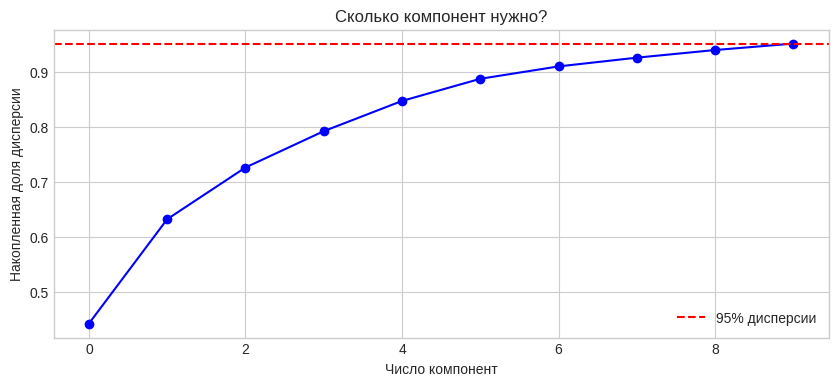

Для 95% дисперсии нужно 10 компонент(ы) из 64.


In [39]:
from sklearn.decomposition import PCA

# Масштабирование (обязательно для PCA!)          # .fit(X) — на данных X он вычисляет статистику: среднее μ j и стандартное отклонение σ j для каждого признака 𝑗. # transform(X) — применяет формулу ... ко всем точкам. #.fit_transform() — это комбинация: сначала обучился на X, потом сразу преобразовал X.
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=0.95)
#pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# График каменистой осыпи (Scree Plot)
plt.figure(figsize=(10, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), 'bo-')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
plt.xlabel('Число компонент')
plt.ylabel('Накопленная доля дисперсии')
plt.title('Сколько компонент нужно?')
plt.legend()
plt.grid(True)
plt.show()

print(f"Для 95% дисперсии нужно {np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1} компонент(ы) из 64.")

4. **Обучите ту же модель на сжатых признаках. Упало ли качество? Насколько сильно?**


In [40]:
# Подготовка данных # ручная перемешка через индексы
rng = np.random.default_rng(42) # seed
indices = np.arange(len(X))
rng.shuffle(indices)

n = len(indices)
n_train = int(n * 0.7)
n_val   = int(n * 0.2)
# n_test = n - n_train - n_val

train_idx = indices[:n_train]
val_idx   = indices[n_train:n_train+n_val]
test_idx  = indices[n_train+n_val:]

X_train_comp, y_train_comp = X_pca[train_idx], y_true[train_idx]
X_val_comp,   y_val_comp   = X_pca[val_idx],   y_true[val_idx]
X_test_comp,  y_test_comp  = X_pca[test_idx],  y_true[test_idx]

In [41]:
rf_compressed = RandomForestClassifier(class_weight='balanced', n_estimators=200, random_state=42)           # n_estimators - количество деревьев в лесу
rf_compressed.fit(X_train_comp, y_train_comp)

train_acc_compressed = accuracy_score(y_train_comp, rf_compressed.predict(X_train_comp))
val_acc_compressed   = accuracy_score(y_val_comp,   rf_compressed.predict(X_val_comp))
print(f"Random Forest на исходных данных: train={train_acc:.3f}, val={val_acc:.3f}")
print(f"Random Forest на сжатых признаках: train={train_acc_compressed:.3f}, val={val_acc_compressed:.3f}")

Random Forest на исходных данных: train=1.000, val=0.956
Random Forest на сжатых признаках: train=1.000, val=0.938


Итог: качество упало, но не критично.

5. **Попробуйте визуализировать данные через `UMAP` и раскрасить по целевому классу (malignant/benign).**

In [42]:
# Установка UMAP (в Colab или локально)
%pip install umap-learn -q

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


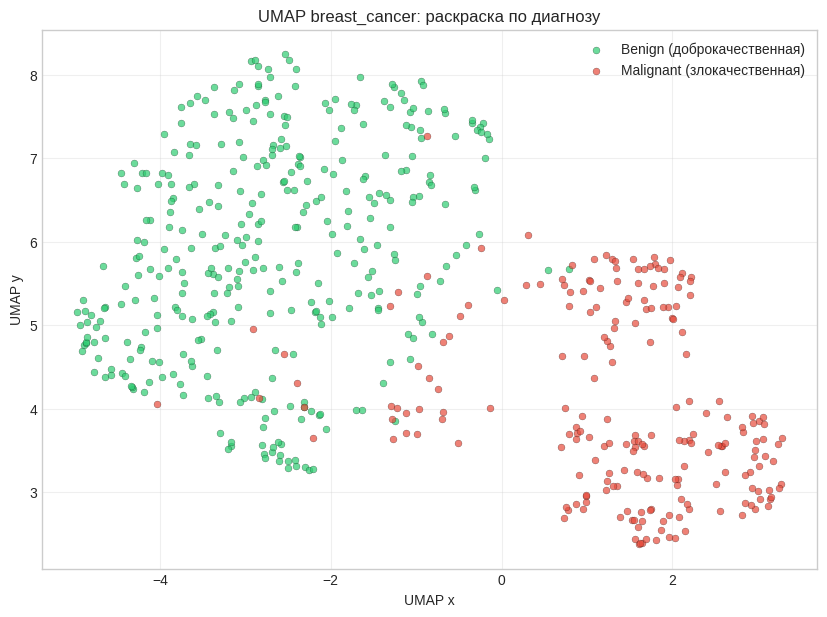

In [63]:
import umap

# UMAP-проекция
reducer = umap.UMAP(n_components=2, # 2 класса
                    n_neighbors=20,  # сколько соседей учитывать
                    min_dist=0.1,   # насколько плотно точки слипаются в кластерах
                    random_state=42)
X_umap = reducer.fit_transform(X_scaled)

# Раскраска по целевому классу
plt.figure(figsize=(10, 7))
colors = ['#2ecc71', '#e74c3c']   # benign — зелёный, malignant — красный
labels = ['Benign (доброкачественная)', 'Malignant (злокачественная)']

for cls, color, label in zip([1, 0], colors, labels):
    mask = y_true == cls
    plt.scatter(X_umap[mask, 0], X_umap[mask, 1],
                c=color, s=25, alpha=0.7, edgecolor='k', linewidth=0.2, label=label)

#plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y_true, cmap='tab10', s=15)
plt.title('UMAP breast_cancer: раскраска по диагнозу')
plt.xlabel('UMAP x'); plt.ylabel('UMAP y')
plt.legend()
plt.grid(alpha=0.3)
plt.show()